# Занятие 3. Скорости, матрица Якоби, кинематические характеристики — демонстрации

Учебник: гл. 3 (§ 3.1–3.4, 3.6). Библиотека `kinlib.py`.
**Внимание:** в `RobotSerial.jacobian` строки идут в порядке $[\mathbf v;\ \boldsymbol\omega]$, в книге — $[\boldsymbol\omega;\ \mathbf v]$; метод `jacobian_book()` переставляет блоки.

| № | Демонстрация | Слайды | Книга |
|---|---|---|---|
| 1 | $\dot R = \Lambda R$: кососимметрическая матрица и угловая скорость численно | 5–6 | § 3.1 |
| 2 | Якобиан по столбцам против численного дифференцирования ПЗК | 12–14 | (3.62) |
| 3 | Двухзвенник: $\det J$, сингулярные числа, вырожденные конфигурации | 18–19, 24 | пример 3.2 |
| 4 | Прямая задача о скорости: вектор скорости схвата | 12 | (3.63) |
| 5 | ОЗК о скорости 6R: рост $\|\dot{\mathbf q}\|$ у особой точки | 23–26 | § 3.4.2–3.4.3 |
| 6 | Избыточный плоский 3R: псевдообратная и самодвижение | 27–29 | § 3.4.4 |
| 7 | Сфера, эллипс и многоугольник допустимых скоростей | 32–34 | примеры 3.5, 3.6 |
| 8 | Мобильность по рабочей зоне; манипулятивность 6R | 35–36 | § 3.6.2 |
| 9 | Приемистость: многоугольник ускорений из покоя | 37 | § 3.6.3 |
| 10 | Интерактив: эллипс скоростей при движении ползунков | — | — |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))          # kinlib.py лежит рядом с ноутбуком
import numpy as np
import matplotlib.pyplot as plt
from kinlib import *
np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

## 1. Вращение твёрдого тела: $\dot R = \Lambda(\boldsymbol\omega) R$ численно (§ 3.1)

Возьмём вращение с постоянной угловой скоростью $\boldsymbol\omega$, найдём $\dot R$ конечными разностями и убедимся, что $\dot R R^{\mathrm T}$ — кососимметрическая матрица, из которой «читается» $\boldsymbol\omega$ (формулы (3.5), (3.11)).
Скорость точки: $\mathbf v_M = \mathbf v_0 + \boldsymbol\omega \times \tilde{\mathbf r}$ (3.7).

In [2]:
from scipy.spatial.transform import Rotation
w = np.array([0.3, -0.5, 1.0])                        # угловая скорость, рад/с
R = lambda t: Rotation.from_rotvec(w * t).as_matrix()
t0, h = 0.7, 1e-6
Rdot = (R(t0 + h) - R(t0 - h)) / (2*h)
S = Rdot @ R(t0).T
print('Λ = Ṙ Rᵀ =\n', S.round(4), '\nΛ + Λᵀ =\n', (S + S.T).round(6))
print('vee(Λ) =', vee(S).round(4), '  ω =', w, '  skew(ω) == Λ:', np.allclose(skew(w), S, atol=1e-5))

# скорость точки тела: r(t) = p + R(t) r'
rp = np.array([0.5, 0.2, -0.3]); v0 = np.array([0.1, 0.0, 0.0])
r = lambda t: v0 * t + R(t) @ rp
v_num = (r(t0 + h) - r(t0 - h)) / (2*h)
print('v_M численно  =', v_num.round(4), '\nv_0 + ω×(R r\') =', (v0 + np.cross(w, R(t0) @ rp)).round(4))

Λ = Ṙ Rᵀ =
 [[ 0.  -1.  -0.5]
 [ 1.   0.  -0.3]
 [ 0.5  0.3  0. ]] 
Λ + Λᵀ =
 [[ 0.  0. -0.]
 [ 0.  0. -0.]
 [-0. -0.  0.]]
vee(Λ) = [ 0.3 -0.5  1. ]   ω = [ 0.3 -0.5  1. ]   skew(ω) == Λ: True
v_M численно  = [-0.4007  0.3172  0.3088] 
v_0 + ω×(R r') = [-0.4007  0.3172  0.3088]


## 2. Якобиан по столбцам против численного дифференцирования (формула (3.62))

Столбец для вращательного сочленения $\mathbf j_k = (\mathbf z_{k-1}\times\mathbf p_{k-1,N};\ \mathbf z_{k-1})$ (в порядке `kinlib`). Сравним с конечными разностями по ПЗК.

In [3]:
robot = make_ur()
q = np.array([0.3, -0.5, 0.8, 0.2, 0.9, -0.4])
J = robot.forward(q) and robot.jacobian
Jn = jacobian_numeric(robot, q)
print('J (столбцы по (3.62)), строки [v; ω]:\n', J.round(4))
print('\nмаксимальное расхождение с численным якобианом: %.2e' % np.abs(J - Jn).max())
print('det J = %.4f, сингулярные числа: %s' % (np.linalg.det(J), np.linalg.svd(J, compute_uv=False).round(3)))

J (столбцы по (3.62)), строки [v; ω]:
 [[-0.0493 -0.665   0.1352  0.0183  0.0036  0.    ]
 [ 1.0382 -0.2057  0.0418  0.0057  0.0782  0.    ]
 [ 0.      1.0064 -0.7034  0.1247 -0.0521 -0.    ]
 [ 0.      0.2955 -0.2955  0.2955  0.8514  0.5231]
 [ 0.     -0.9553  0.9553 -0.9553  0.2634 -0.4888]
 [ 1.      0.     -0.      0.      0.4536 -0.6981]]

максимальное расхождение с численным якобианом: 5.19e-07
det J = 0.2075, сингулярные числа: [2.21  1.566 0.984 0.779 0.412 0.19 ]


## 3. Двухзвенник: $\det J_v = a^2 \sin q_2$ и вырожденные конфигурации (пример 3.2)

При $q_2 = \pi n$ ранг падает до 1: скорость схвата возможна только перпендикулярно руке.

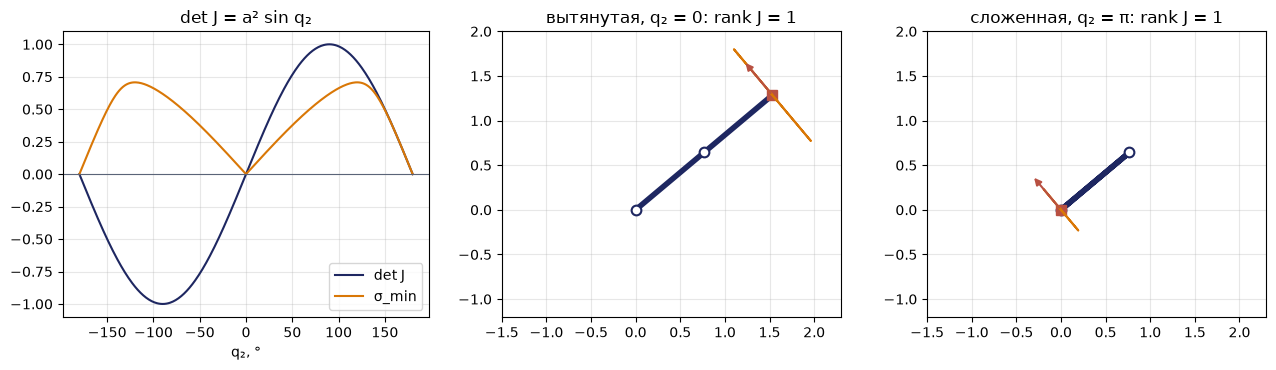

In [4]:
l = (1.0, 1.0)
q2s = np.linspace(-np.pi, np.pi, 361)
det = [np.linalg.det(jac2r((0.4, q2), l)) for q2 in q2s]
sv = np.array([np.linalg.svd(jac2r((0.4, q2), l), compute_uv=False) for q2 in q2s])
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
axs[0].plot(np.degrees(q2s), det, color=NAVY, label='det J'); axs[0].plot(np.degrees(q2s), sv[:, 1], color=AMB, label='σ_min')
axs[0].axhline(0, color=GREY, lw=.8); axs[0].set_xlabel('q₂, °'); axs[0].legend(); axs[0].grid(alpha=.3); axs[0].set_title('det J = a² sin q₂')
for ax, q2, name in zip(axs[1:], (0.0, np.pi), ('вытянутая, q₂ = 0', 'сложенная, q₂ = π')):
    q = (np.radians(40), q2); J = jac2r(q, l)
    pts = draw_arm2d(ax, q, l)
    e = ellipse_image(J, 0.3); ax.plot(pts[-1, 0] + e[:, 0], pts[-1, 1] + e[:, 1], color=AMB)
    U, S, Vt = np.linalg.svd(J)
    ax.annotate('', pts[-1] + 0.5 * U[:, 0], pts[-1], arrowprops=dict(arrowstyle='-|>', color=RED, lw=1.5))
    ax.set_aspect('equal'); ax.set_xlim(-1.5, 2.3); ax.set_ylim(-1.2, 2.0); ax.grid(alpha=.3)
    ax.set_title('%s: rank J = %d' % (name, np.linalg.matrix_rank(J, tol=1e-9)))
plt.tight_layout(); plt.show()

## 4. Прямая задача о скорости: $\mathbf v = J(\mathbf q)\dot{\mathbf q}$

Скорость схвата как сумма вкладов сочленений: каждый столбец — скорость от «своего» сочленения.

v = J q̇ = [-0.04   0.433]    конечная разность ПЗК: [-0.04   0.433]


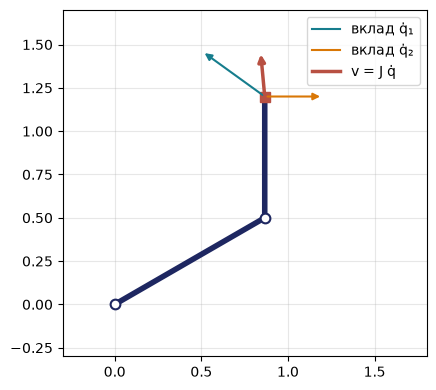

In [5]:
l = (1.0, 0.7); q = np.radians([30, 60]); qd = np.array([0.5, -0.8])
J = jac2r(q, l); v = J @ qd
p0, _ = fk2r(q, l); p1, _ = fk2r(q + 1e-6 * qd, l)
print('v = J q̇ =', v.round(4), '   конечная разность ПЗК:', ((p1 - p0) / 1e-6).round(4))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
pts = draw_arm2d(ax, q, l)
for j, col, name in ((0, TEAL, 'вклад q̇₁'), (1, AMB, 'вклад q̇₂')):
    ax.annotate('', pts[-1] + 0.6 * J[:, j] * qd[j], pts[-1], arrowprops=dict(arrowstyle='-|>', color=col, lw=1.5)); ax.plot([], [], color=col, label=name)
ax.annotate('', pts[-1] + 0.6 * v, pts[-1], arrowprops=dict(arrowstyle='-|>', color=RED, lw=2.5)); ax.plot([], [], color=RED, lw=2.5, label='v = J q̇')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(); ax.set_xlim(-0.3, 1.8); ax.set_ylim(-0.3, 1.7); plt.show()

## 5. ОЗК о скорости 6R: что происходит у особой точки (§ 3.4.2)

Пусть схват должен двигаться со скоростью $\dot{\mathbf s}^* = (0{,}1\ \text{м/с по } x;\ \boldsymbol\omega = 0)$. Решаем $\dot{\mathbf q} = J^{+}\dot{\mathbf s}^*$ вдоль пути в пространстве конфигураций, проходящего через кистевую особенность ($q_5 = 0$: оси 4-го и 6-го сочленений совпадают). Норма скоростей приводов растёт как $1/\sigma_{\min}$.

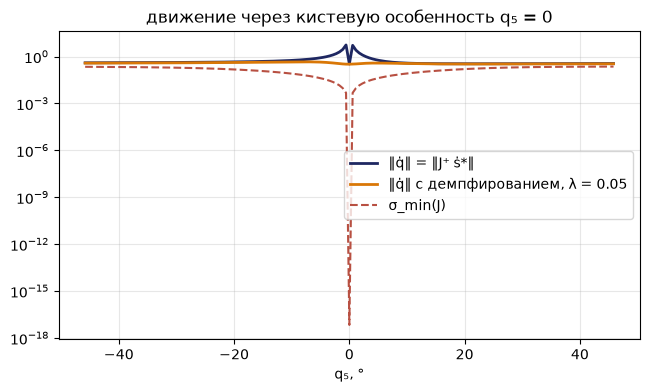

In [6]:
robot = make_ur()
s_cmd = np.array([0.1, 0, 0, 0, 0, 0])
q5 = np.linspace(-0.8, 0.8, 161)
norms, smin, norms_dls = [], [], []
for v5 in q5:
    q = np.array([0.4, -0.6, 1.0, -0.4, v5, 0.3]); robot.forward(q); J = robot.jacobian
    norms.append(np.linalg.norm(np.linalg.pinv(J) @ s_cmd))
    norms_dls.append(np.linalg.norm(J.T @ np.linalg.solve(J @ J.T + 0.05**2 * np.eye(6), s_cmd)))
    smin.append(np.linalg.svd(J, compute_uv=False).min())
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.semilogy(np.degrees(q5), norms, color=NAVY, lw=2, label='‖q̇‖ = ‖J⁺ ṡ*‖')
ax.semilogy(np.degrees(q5), norms_dls, color=AMB, lw=2, label='‖q̇‖ с демпфированием, λ = 0.05')
ax.semilogy(np.degrees(q5), smin, color=RED, ls='--', label='σ_min(J)')
ax.set_xlabel('q₅, °'); ax.grid(alpha=.3); ax.legend(); ax.set_title('движение через кистевую особенность q₅ = 0'); plt.show()

## 6. Избыточный плоский 3R: псевдообратная и самодвижение (§ 3.4.4)

Задано только положение схвата (2 уравнения, 3 неизвестных). Общее решение $\dot{\mathbf q} = J^{+}\mathbf v + (E - J^{+}J)\boldsymbol\xi$:
первое слагаемое — минимальная норма, второе — движение в ядре якобиана, при котором схват стоит на месте.

схват сместился на 5.01e-03 (должен стоять на месте)


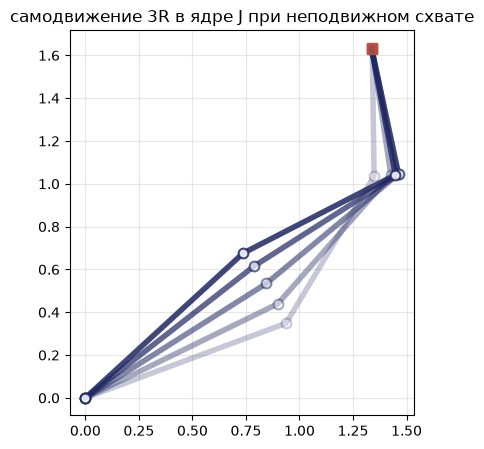

J⁺v = [-0.059 -0.049 -0.1  ] ‖·‖ = 0.126;   другое решение [ 0.129 -0.432 -0.023] ‖·‖ = 0.451;  J q̇ одинаково: True


In [7]:
l = (1.0, 0.8, 0.6)
q = np.radians([20, 40, 30]); v = np.array([0.0, 0.0])
fig, ax = plt.subplots(figsize=(6, 5))
p_start, _ = fk_planar(q, l); p_start = p_start[-1]
dt = 0.05
for k in range(60):
    J = jac_planar(q, l)[:2]                        # только положение
    Jp = np.linalg.pinv(J)
    xi = np.array([0.0, 0.0, 1.0])                  # «желание» двигать третье сочленение
    qd = Jp @ v + (np.eye(3) - Jp @ J) @ xi         # v = 0: чистое самодвижение
    q = q + dt * qd
    if k % 12 == 0:
        draw_arm2d(ax, q, l, color=NAVY, alpha=0.25 + 0.75 * k / 60)
p_end, _ = fk_planar(q, l)
print('схват сместился на %.2e (должен стоять на месте)' % np.linalg.norm(p_end[-1] - p_start))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('самодвижение 3R в ядре J при неподвижном схвате'); plt.show()

# минимальная норма: сравним J⁺ v с другим решением из того же семейства
J = jac_planar(q, l)[:2]; Jp = np.linalg.pinv(J); v = np.array([0.2, -0.1])
q1 = Jp @ v; q2 = q1 + (np.eye(3) - Jp @ J) @ np.array([1., 0, 0])
print('J⁺v =', q1.round(3), '‖·‖ = %.3f;   другое решение' % np.linalg.norm(q1), q2.round(3), '‖·‖ = %.3f;  J q̇ одинаково:' % np.linalg.norm(q2), np.allclose(J @ q1, J @ q2))

## 7. Сфера, эллипс и многоугольник допустимых скоростей (примеры 3.5, 3.6)

$l_1 = l_2 = 1$, $|\dot q_1| \le 0{,}1$, $|\dot q_2| \le 0{,}5$ рад/с, $C = \sqrt{0{,}1^2 + 0{,}5^2} = 0{,}51$. В точке $\mathbf q = (0, \pi/2)$:
сфера радиуса $\sqrt{\lambda^*}C$ (3.184), эллипс — образ круга $\|\dot{\mathbf q}\| \le C$ (3.185), многоугольник — образ прямоугольника ограничений (точная, гарантированная оценка).

λ(JᵀJ) = [0.382 2.618]   радиус сферы √λ*·C = 0.825
полуоси эллипса C√λ = 0.825, 0.315
вершины многоугольника:
 [[-0.6  0.1]
 [-0.4 -0.1]
 [ 0.6 -0.1]
 [ 0.4  0.1]] 
макс. и мин. расстояние до вершин: 0.608, 0.412 (книга: 0,62 и 0,41)


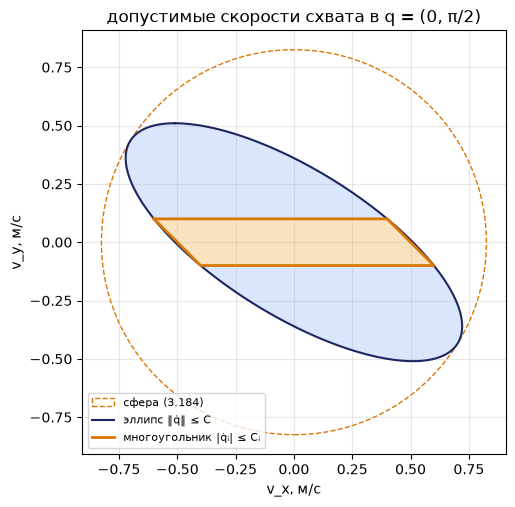

In [8]:
l = (1.0, 1.0); C = np.array([0.1, 0.5]); q = (0.0, np.pi/2)
J = jac2r(q, l)
r_sph, lam = sphere_radius(J, C)
ell = ellipse_image(J, np.linalg.norm(C)); poly = polygon_image(J, C)
print('λ(JᵀJ) =', lam.round(3), '  радиус сферы √λ*·C = %.3f' % r_sph)
print('полуоси эллипса C√λ = %.3f, %.3f' % tuple(np.linalg.norm(C) * np.sqrt(lam[::-1])))
print('вершины многоугольника:\n', poly.round(2), '\nмакс. и мин. расстояние до вершин: %.3f, %.3f (книга: 0,62 и 0,41)' % (np.linalg.norm(poly, axis=1).max(), np.linalg.norm(poly, axis=1).min()))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.add_patch(plt.Circle((0, 0), r_sph, fill=False, ls='--', color=AMB, label='сфера (3.184)'))
ax.fill(ell[:, 0], ell[:, 1], color=ICE, alpha=.7); ax.plot(ell[:, 0], ell[:, 1], color=NAVY, label='эллипс ‖q̇‖ ≤ C')
ax.fill(poly[:, 0], poly[:, 1], color='#FFE2B8', alpha=.9); ax.plot(np.r_[poly[:, 0], poly[0, 0]], np.r_[poly[:, 1], poly[0, 1]], color=AMB, lw=2, label='многоугольник |q̇ᵢ| ≤ Cᵢ')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(loc='lower left', fontsize=8); ax.set_xlabel('v_x, м/с'); ax.set_ylabel('v_y, м/с')
ax.set_title('допустимые скорости схвата в q = (0, π/2)'); plt.show()

## 8. Мобильность по рабочей зоне и манипулятивность 6R (§ 3.6.2)

Мобильность $M(\mathbf q)$ — площадь многоугольника скоростей; для 2R $M = |\det J_v|\cdot 4C_1C_2$. Для 6R показываем меру $\sqrt{\det(J_vJ_v^{\mathrm T})}$ (объём эллипсоида) в плоскости $(q_2, q_3)$ — нули на вырожденных конфигурациях.

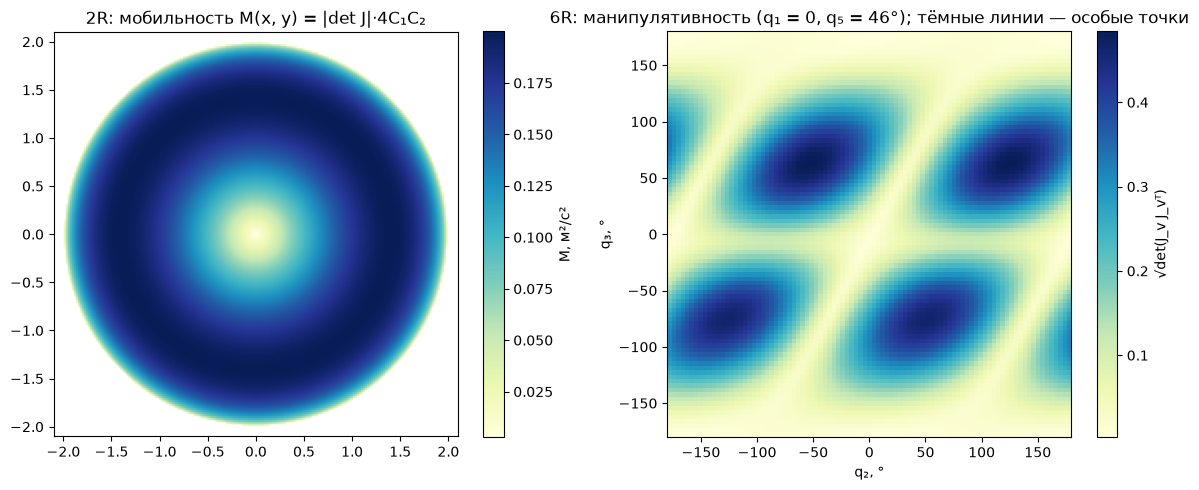

In [9]:
# 2R: карта мобильности
l = (1.0, 1.0); C = np.array([0.1, 0.5])
N = 200; xs = np.linspace(-2.1, 2.1, N); X, Y = np.meshgrid(xs, xs)
M = np.full_like(X, np.nan)
for i in range(N):
    for j in range(N):
        sols = ik2r(X[i, j], Y[i, j], l)
        if sols:
            M[i, j] = abs(np.linalg.det(jac2r(sols[0], l))) * 4 * C[0] * C[1]
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
im = axs[0].imshow(M, extent=[xs[0], xs[-1], xs[0], xs[-1]], origin='lower', cmap='YlGnBu'); plt.colorbar(im, ax=axs[0], label='M, м²/с²')
axs[0].set_aspect('equal'); axs[0].set_title('2R: мобильность M(x, y) = |det J|·4C₁C₂')

# 6R: мера манипулятивности в плоскости (q2, q3)
robot = make_ur()
q2s = np.linspace(-np.pi, np.pi, 91); q3s = np.linspace(-np.pi, np.pi, 91)
W = np.zeros((len(q3s), len(q2s)))
for i, q3 in enumerate(q3s):
    for j, q2 in enumerate(q2s):
        robot.forward(np.array([0.0, q2, q3, 0.0, 0.8, 0.0]))
        W[i, j] = manipulability(robot.jacobian[0:3])
im2 = axs[1].imshow(W, extent=[-180, 180, -180, 180], origin='lower', cmap='YlGnBu', aspect='auto'); plt.colorbar(im2, ax=axs[1], label='√det(J_v J_vᵀ)')
axs[1].set_xlabel('q₂, °'); axs[1].set_ylabel('q₃, °'); axs[1].set_title('6R: манипулятивность (q₁ = 0, q₅ = 46°); тёмные линии — особые точки')
plt.tight_layout(); plt.show()

## 9. Приемистость: многоугольник ускорений из покоя (§ 3.6.3)

При $\dot{\mathbf q} = 0$: $\mathbf w_N = J_v\ddot{\mathbf q}$ — та же линейная структура; ограничения $|\ddot q_i| \le b_i$ дают многоугольник допустимых ускорений $D_w$.

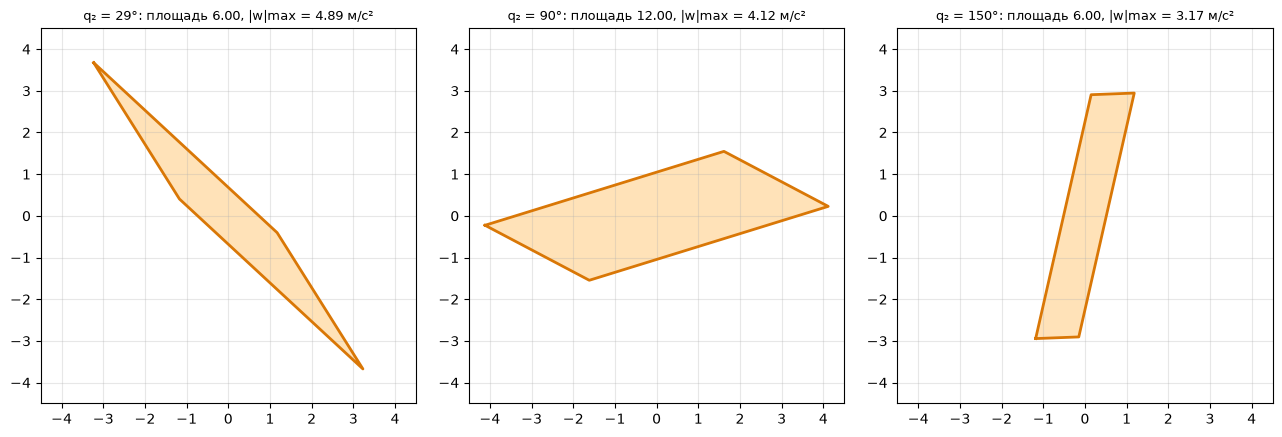

оговорка авторов: это чисто кинематическая (завышенная) оценка — реальные ускорения ограничены моментами приводов и инерцией (гл. 5)


In [10]:
l = (1.0, 1.0); b = np.array([1.0, 3.0])   # рад/с²
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, q2 in zip(axs, (np.pi/6, np.pi/2, 5*np.pi/6)):
    J = jac2r((0.3, q2), l); D = polygon_image(J, b)
    ax.fill(D[:, 0], D[:, 1], color='#FFE2B8'); ax.plot(np.r_[D[:, 0], D[0, 0]], np.r_[D[:, 1], D[0, 1]], color=AMB, lw=2)
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5)
    ax.set_title('q₂ = %d°: площадь %.2f, |w|max = %.2f м/с²' % (np.degrees(q2), abs(np.linalg.det(J)) * 4 * b[0] * b[1], np.linalg.norm(D, axis=1).max()), fontsize=9)
plt.tight_layout(); plt.show()
print('оговорка авторов: это чисто кинематическая (завышенная) оценка — реальные ускорения ограничены моментами приводов и инерцией (гл. 5)')

## 10. Интерактив: эллипс скоростей 2R при движении ползунков (запускать вживую)

In [11]:
try:
    from ipywidgets import interact, FloatSlider
    def show_ellipse(q1=30., q2=60.):
        l = (1.0, 0.7); q = np.radians([q1, q2]); J = jac2r(q, l)
        fig, ax = plt.subplots(figsize=(5.5, 5)); pts = draw_arm2d(ax, q, l)
        e = ellipse_image(J, 0.4); ax.plot(pts[-1, 0] + e[:, 0], pts[-1, 1] + e[:, 1], color=AMB, lw=2)
        ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-1.9, 1.9); ax.set_ylim(-1.9, 1.9)
        ax.set_title('det J = %.3f, σ = %s, манипулятивность %.3f' % (np.linalg.det(J), np.linalg.svd(J, compute_uv=False).round(2), manipulability(J))); plt.show()
    interact(show_ellipse, q1=FloatSlider(min=-180, max=180, step=5, value=30), q2=FloatSlider(min=-180, max=180, step=5, value=60))
except ImportError:
    print('установите ipywidgets: pip install ipywidgets')

interactive(children=(FloatSlider(value=30.0, description='q1', max=180.0, min=-180.0, step=5.0), FloatSlider(…